In [1]:
# Import essential data analysis, numerical calculation, and visualization libraries
import pandas as pd  # Data manipulation library
import numpy as np   # Multi-dimensional arrays and mathematical operations
import matplotlib.pyplot as mplt  # Plotting library for static charts
import seaborn as sns  # Advanced plotting built on top of matplotlib

In [2]:
# Define the local system path to the CSV file dataset
path = "/content/P721 DATASET.csv"

# Read the comma-separated values (CSV) into a pandas DataFrame object named 'data'
data = pd.read_csv(path)

In [3]:
# Print a concise summary of the DataFrame including index type, column types, non-null values, and memory usage
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2011 entries, 0 to 2010
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2011 non-null   object 
 1   Open       2011 non-null   float64
 2   High       2011 non-null   float64
 3   Low        2011 non-null   float64
 4   Close      2011 non-null   float64
 5   Adj Close  2011 non-null   float64
 6   Volume     2011 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 110.1+ KB


In [4]:
# Generate descriptive statistics summarizing central tendency, dispersion, and shape of the dataset numerical columns
data.describe()

,Open,High,Low,Close,Adj Close,Volume
count,2011.000000,2011.000000,2011.000000,2011.000000,2011.000000,2.011000e+03
mean,126.707469,127.827594,125.580258,126.741235,119.505548,5.949670e+07
std,50.483753,50.926301,50.124940,50.578369,52.438444,4.683856e+07
min,55.424286,57.085712,55.014286,55.790001,48.921928,1.136200e+07
25%,85.882858,86.717858,85.056427,86.202145,75.056679,2.758565e+07
50%,113.050003,114.190002,111.870003,113.050003,105.222908,4.346900e+07
75%,165.190002,167.409996,163.424995,165.245002,160.047111,7.471030e+07
max,291.119995,293.970001,288.119995,291.519989,289.522614,3.765300e+08


In [5]:
# Retrieve and display the total number of rows present in the dataset (first element of shape tuple)
data.shape[0]

2011

In [6]:
# Retrieve and display the total number of columns present in the dataset (second element of shape tuple)
data.shape[1]

7

In [7]:
# Display the first 5 rows of the DataFrame to inspect the column headers and initial data structure
data.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2012-01-03,58.485714,58.928570,58.428570,58.747143,50.765709,75555200
1,2012-01-04,58.571430,59.240002,58.468571,59.062859,51.038536,65005500
2,2012-01-05,59.278572,59.792858,58.952858,59.718571,51.605175,67817400
3,2012-01-06,59.967144,60.392857,59.888573,60.342857,52.144630,79573200
4,2012-01-09,60.785713,61.107143,60.192856,60.247143,52.061932,98506100


In [8]:
# Check for missing values in each column by summing up the boolean mask of null elements
data.isnull().sum()

,0
Date,0
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0


In [9]:
# Sum up the duplicated rows to identify matches, and convert the final count to an integer
int(data.duplicated().sum())

0

In [10]:
# Re-import visualization packages explicitly for use in subsequent plotting cells
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
# --- Feature Engineering Stage ---
# Calculate the daily fractional percentage change of the Closing price, and scale by 100
data['Daily_return'] = data['Close'].pct_change() * 100
data['Daily_return']

,Daily_return
0,NaN
1,0.537415
2,1.110193
3,1.045380
4,-0.158617
...,...
2006,1.631834
2007,0.095067
2008,1.984035
2009,-0.037948


In [12]:
# Calculate the raw absolute daily price change by subtracting the Open price from the Close price
data['Price_Change'] = data['Close'] - data['Open']
data['Price_Change']

,Price_Change
0,0.261429
1,0.491429
2,0.439999
3,0.375713
4,-0.538570
...,...
2006,3.470001
2007,-0.420013
2008,5.089997
2009,-1.320007


In [13]:
# Calculate the absolute daily trading price range (maximum fluctuation between High and Low price)
Daily_Range = data['High'] - data['Low']
Daily_Range

,0
0,0.500000
1,0.771431
2,0.840000
3,0.504284
4,0.914287
...,...
2006,3.880005
2007,1.970002
2008,5.279999
2009,5.850006


In [14]:
# Calculate the intraday price movement trend (equivalent to price change: Close minus Open)
Open_Closing_Change = data['Close'] - data['Open']
Open_Closing_Change

,0
0,0.261429
1,0.491429
2,0.439999
3,0.375713
4,-0.538570
...,...
2006,3.470001
2007,-0.420013
2008,5.089997
2009,-1.320007


In [15]:
# Calculate relative daily volatility as a percentage of the closing price
data['High_low_pct'] = (data['High'] - data['Low']) / data['Close'] * 100
data['High_low_pct']

,High_low_pct
0,0.851105
1,1.306119
2,1.406598
3,0.835698
4,1.517561
...,...
2006,1.366199
2007,0.693004
2008,1.821255
2009,2.018636


In [16]:
# Create historical lag features to allow models to observe recent patterns
# Lag historical Close prices by 1, 2, 3, and 5 periods
for lag in [1, 2, 3, 5]:
    data[f'Close_Lag_{lag}'] = data['Close'].shift(lag)

# Lag historical Volume values by 1 and 2 periods
for lag in [1, 2]:
    data[f'Volume_Lag_{lag}'] = data['Volume'].shift(lag)

In [17]:
# Calculate rolling Simple Moving Averages (SMA) over windows of 7, 14, and 30 days
data['SMA_7'] = data['Close'].rolling(window=7).mean()
data['SMA_14'] = data['Close'].rolling(window=14).mean()
data['SMA_30'] = data['Close'].rolling(window=30).mean()

# Calculate Exponential Moving Average (EMA) with a span of 14 days for more weight on recent data
data['EMA_14'] = data['Close'].ewm(span=14, adjust=False).mean()

In [18]:
# Ensure the 'Date' column is converted to datetime format for correct date operations
data['Date'] = pd.to_datetime(data['Date'])

# Extract temporal features to help our predictive models detect seasonal trends
data['Day_of_Week'] = data['Date'].dt.dayofweek   # Monday=0, Sunday=6
data['Month'] = data['Date'].dt.month               # Range 1 to 12
data['Quarter'] = data['Date'].dt.quarter         # Range 1 to 4
data['Is_Month_End'] = data['Date'].dt.is_month_end.astype(int)  # 1 if month end, else 0

In [19]:
# Drop empty cells created by the sliding windows of shift/rolling operations
data = data.dropna().reset_index(drop=True)

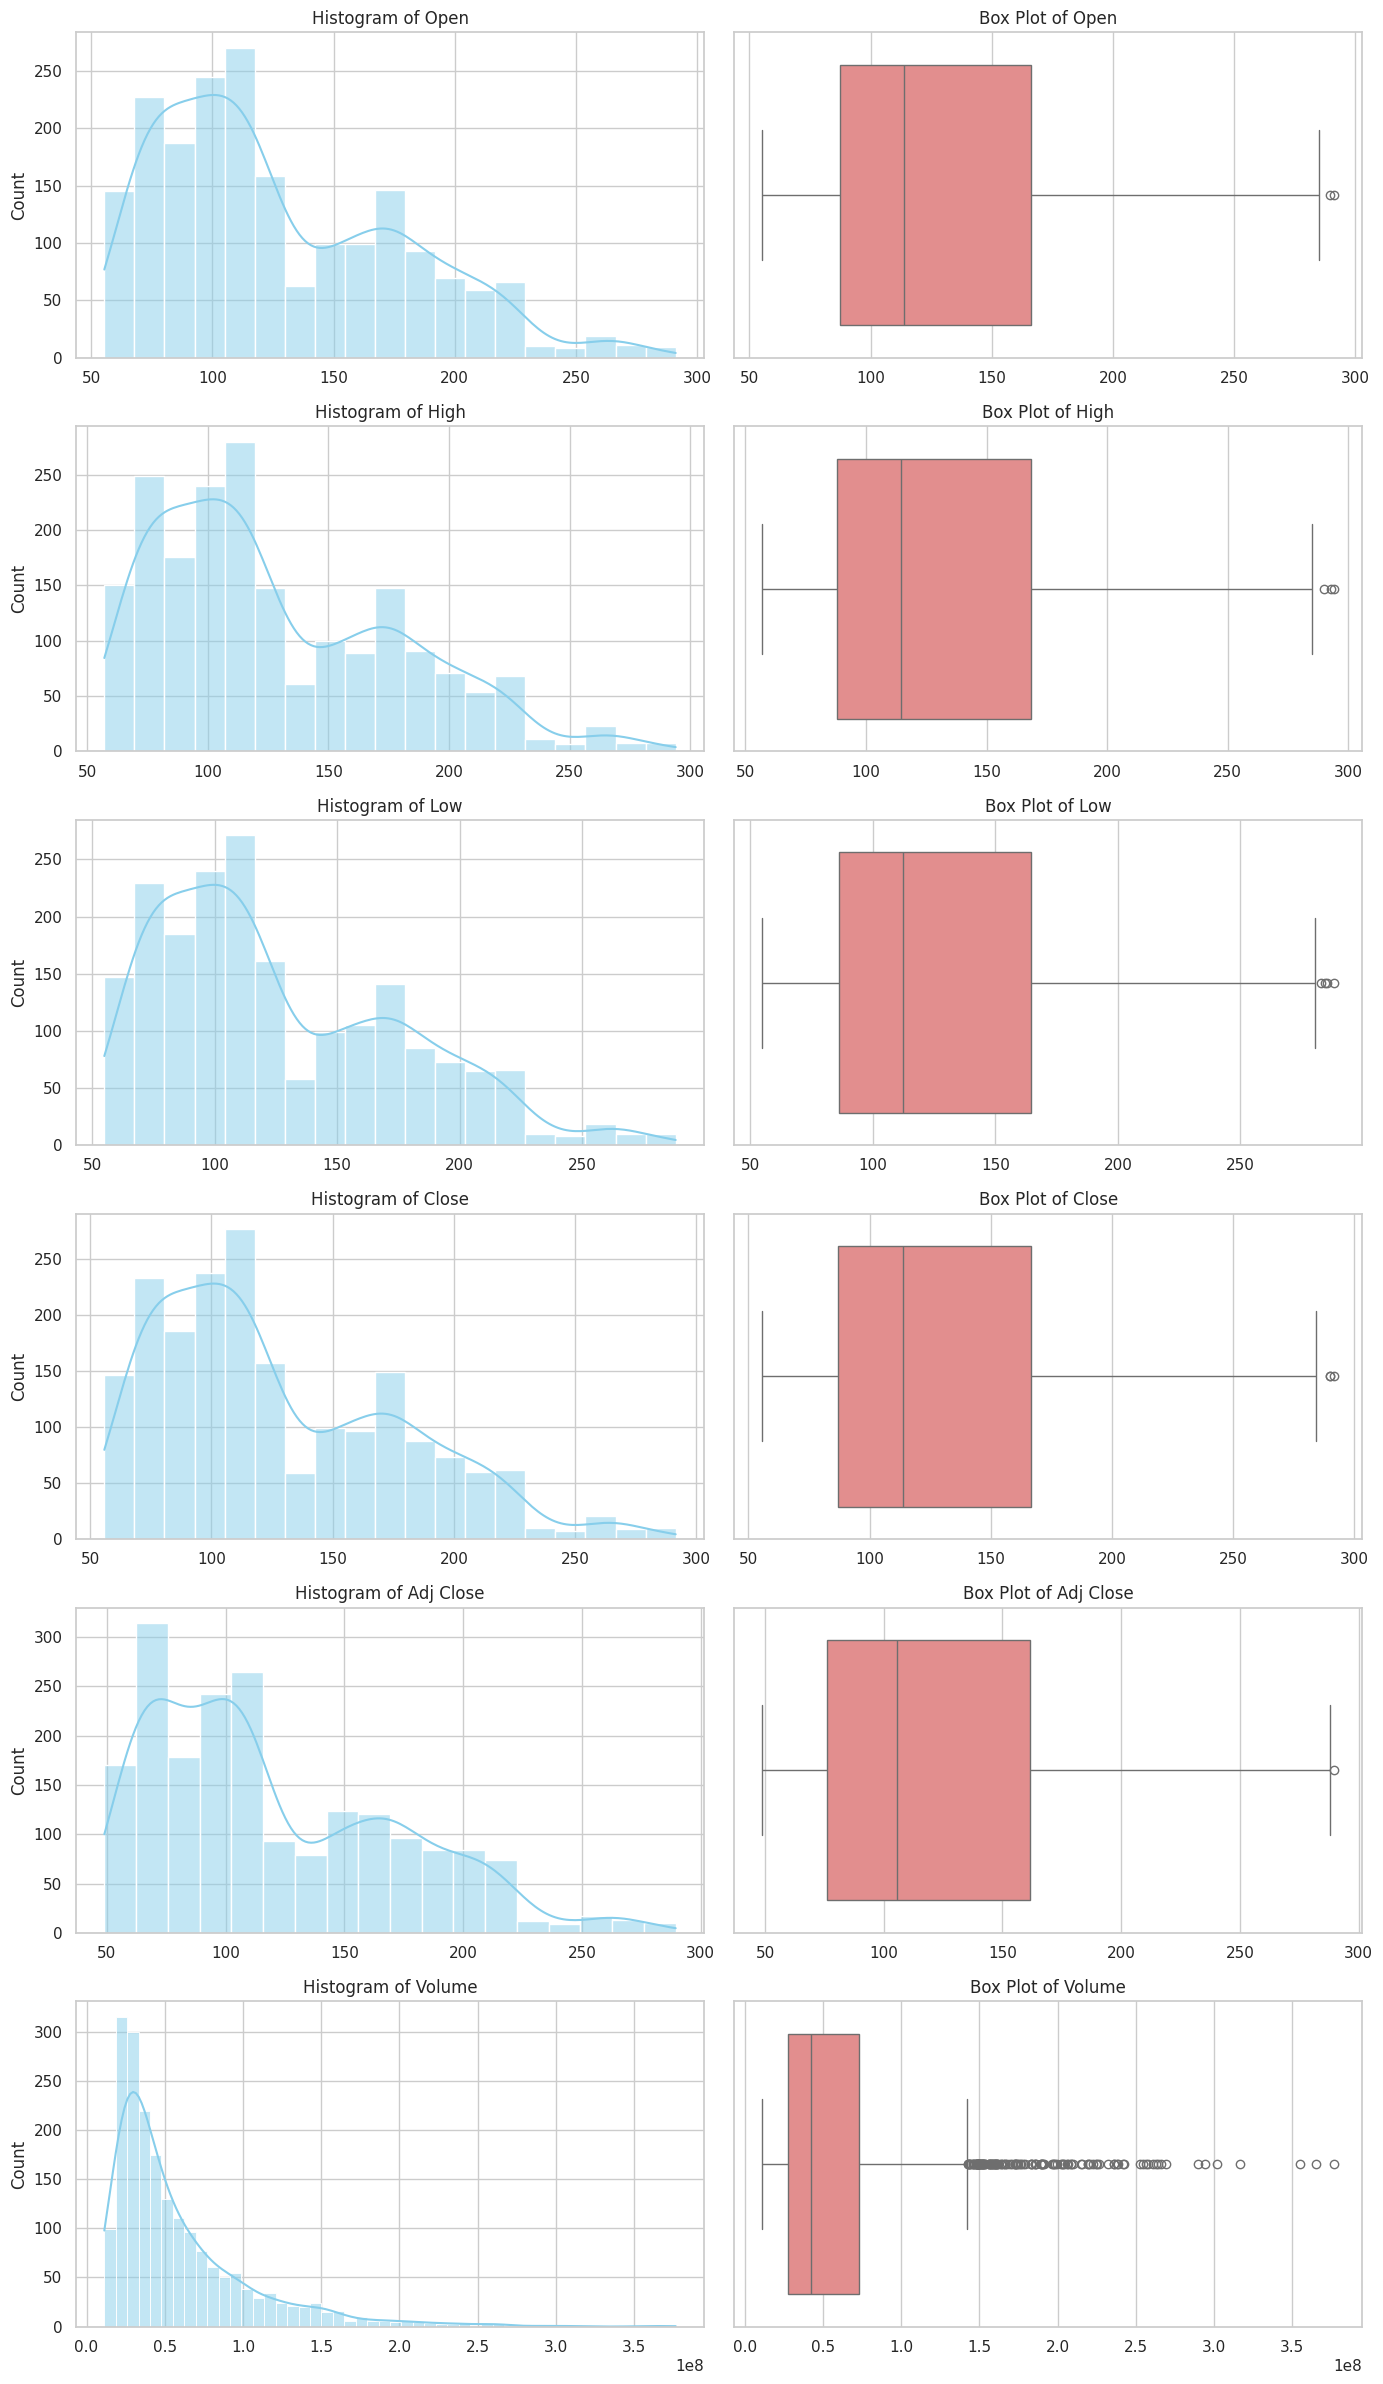

In [20]:
# Visualizing skewness and ranges using static plots
import matplotlib.pyplot as plt
import seaborn as sns

# Select columns to visualize distributions
num_cols = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']

# Establish coordinate system styling
sns.set_theme(style='whitegrid')

# Initialize subplot figure structure
fig, axes = plt.subplots(nrows=len(num_cols), ncols=2, figsize=(14, 4 * len(num_cols)))

# Generate a histogram and a box plot side-by-side for each variable
for i, col in enumerate(num_cols):
    # Left side: Histogram with kernel density estimate overlay
    sns.histplot(data=data, x=col, kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Histogram of {col}', fontsize=12)
    axes[i, 0].set_xlabel('')

    # Right side: Box plot to quickly pinpoint outlines and quartiles
    sns.boxplot(data=data, x=col, ax=axes[i, 1], color='lightcoral')
    axes[i, 1].set_title(f'Box Plot of {col}', fontsize=12)
    axes[i, 1].set_xlabel('')

plt.tight_layout()
plt.show()

In [21]:
# Isolate numerical features to compute their distribution skewness
numeric_cols = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
skewness_values = data[numeric_cols].skew()

print("Skewness for each numerical feature:")
display(skewness_values.to_frame(name='Skewness'))

Skewness for each numerical feature:


,Skewness
Open,0.765618
High,0.767431
Low,0.766739
Close,0.769953
Adj Close,0.789296
Volume,2.186773


Original Volume Skewness: 2.1868
Log-transformed Volume Skewness: 0.4764


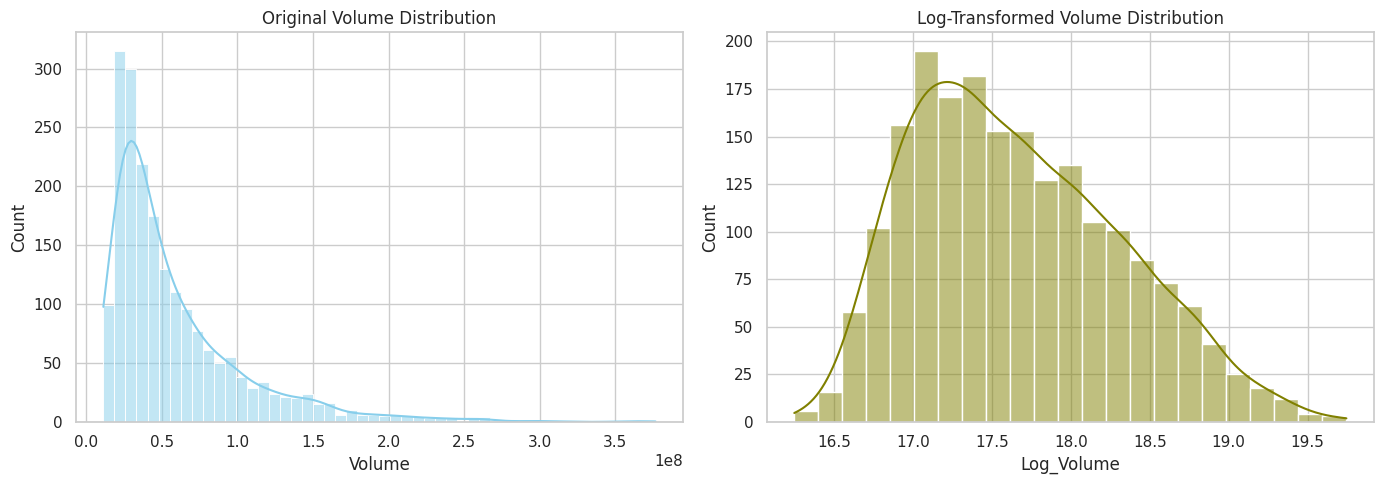

In [22]:
# Apply logarithmic transformation (log(1 + x)) to normalise the skewed Volume column
data['Log_Volume'] = np.log1p(data['Volume'])

# Capture and display the contrast in skewness before and after transformation
original_skew = data['Volume'].skew()
transformed_skew = data['Log_Volume'].skew()
print(f"Original Volume Skewness: {original_skew:.4f}")
print(f"Log-transformed Volume Skewness: {transformed_skew:.4f}")

# Visualize side-by-side comparison of Volume transformations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=data, x='Volume', kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Original Volume Distribution')

sns.histplot(data=data, x='Log_Volume', kde=True, ax=axes[1], color='olive')
axes[1].set_title('Log-Transformed Volume Distribution')

plt.tight_layout()
plt.show()

,Feature,Original Skewness,Log_1p Skewness
0,Open,0.765618,0.153381
1,High,0.767431,0.157395
2,Low,0.766739,0.151323
3,Close,0.769953,0.154027
4,Adj Close,0.789296,0.146635
5,Volume,2.186773,0.476405


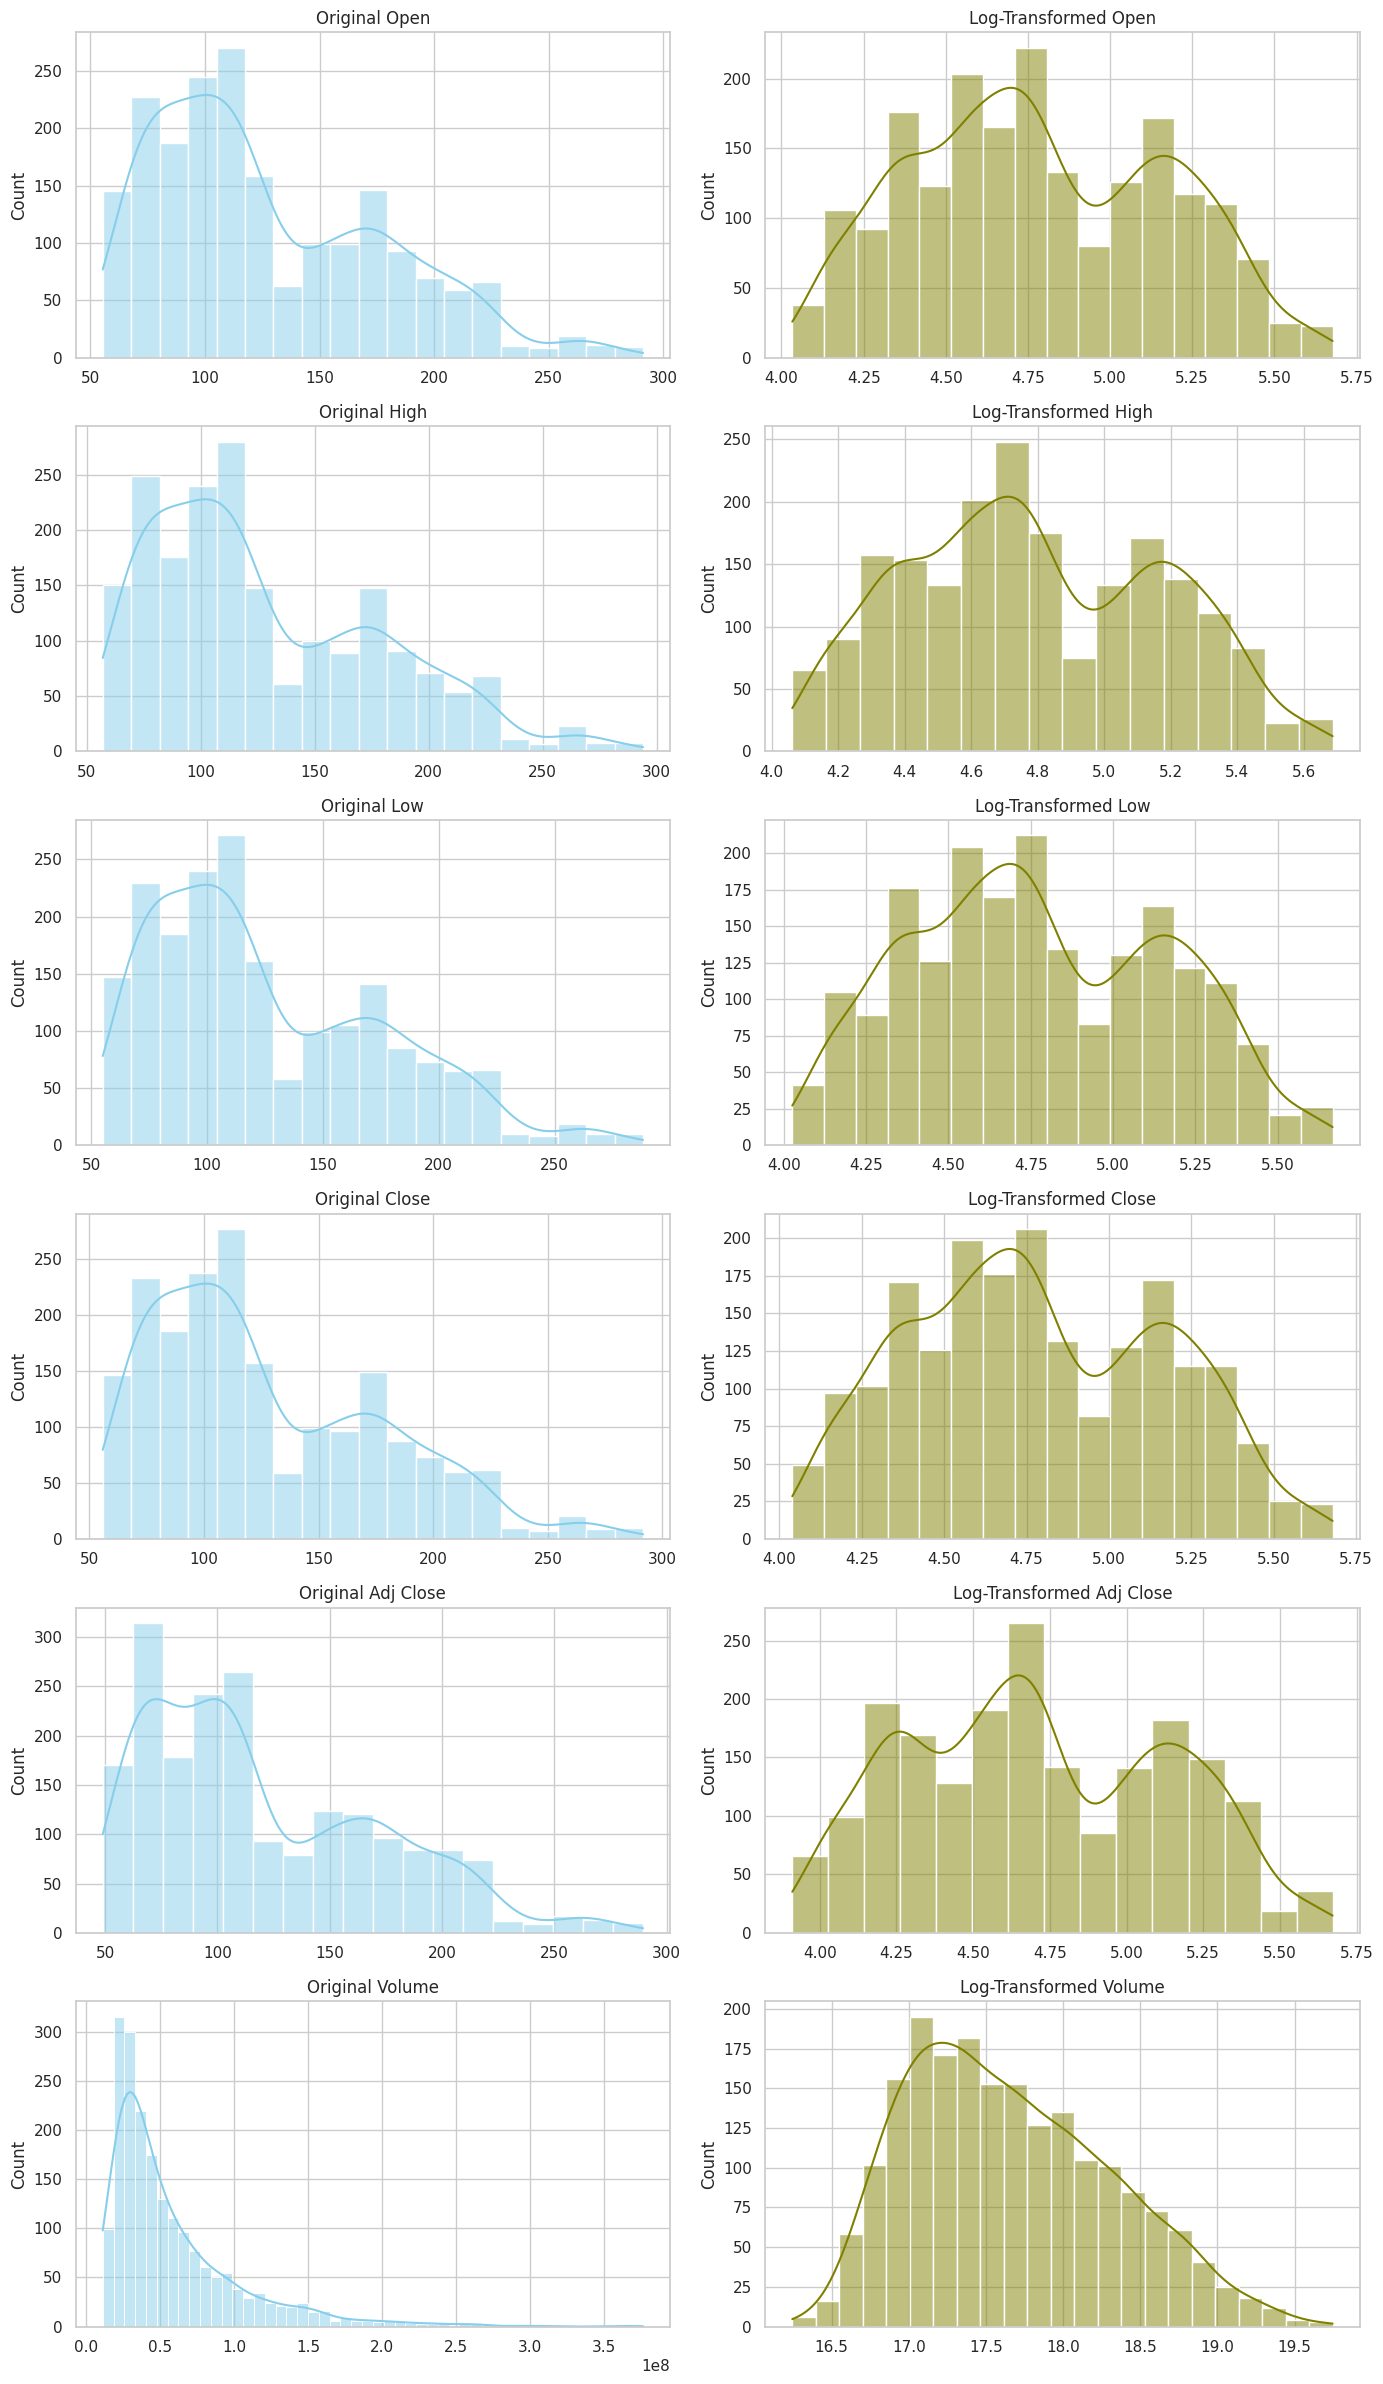

In [23]:
# Apply log1p transformation across all numeric columns to reduce overall skewness
numeric_features = ['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']
for col in numeric_features:
    data[f'Log_{col}'] = np.log1p(data[col])

# Build a performance metrics dictionary to track skew reduction
skew_comparison = []
for col in numeric_features:
    orig_skew = data[col].skew()
    log_skew = data[f'Log_{col}'].skew()
    skew_comparison.append({
        'Feature': col,
        'Original Skewness': orig_skew,
        'Log_1p Skewness': log_skew
    })

display(pd.DataFrame(skew_comparison))

# Plot distribution transformations for visual verification
fig, axes = plt.subplots(nrows=len(numeric_features), ncols=2, figsize=(14, 4 * len(numeric_features)))
for i, col in enumerate(numeric_features):
    # Plot Untransformed Original Distribution
    sns.histplot(data=data, x=col, kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Original {col}')
    axes[i, 0].set_xlabel('')

    # Plot Transformed Normalized Distribution
    sns.histplot(data=data, x=f'Log_{col}', kde=True, ax=axes[i, 1], color='olive')
    axes[i, 1].set_title(f'Log-Transformed {col}')
    axes[i, 1].set_xlabel('')

plt.tight_layout()
plt.show()

In [24]:
# Compile and display the final comparison DataFrame showing skew transformation results
skew_comparison_df = pd.DataFrame({
    'Feature': numeric_features,
    'Original Skewness': [data[col].skew() for col in numeric_features],
    'Log1p Transformed Skewness': [data[f'Log_{col}'].skew() for col in numeric_features]
})

display(skew_comparison_df)

,Feature,Original Skewness,Log1p Transformed Skewness
0,Open,0.765618,0.153381
1,High,0.767431,0.157395
2,Low,0.766739,0.151323
3,Close,0.769953,0.154027
4,Adj Close,0.789296,0.146635
5,Volume,2.186773,0.476405


### Stationarity Testing
To check if our time-series data is stationary, we will:
1. Plot the rolling mean and rolling standard deviation.
2. Run the Augmented Dickey-Fuller (ADF) test.

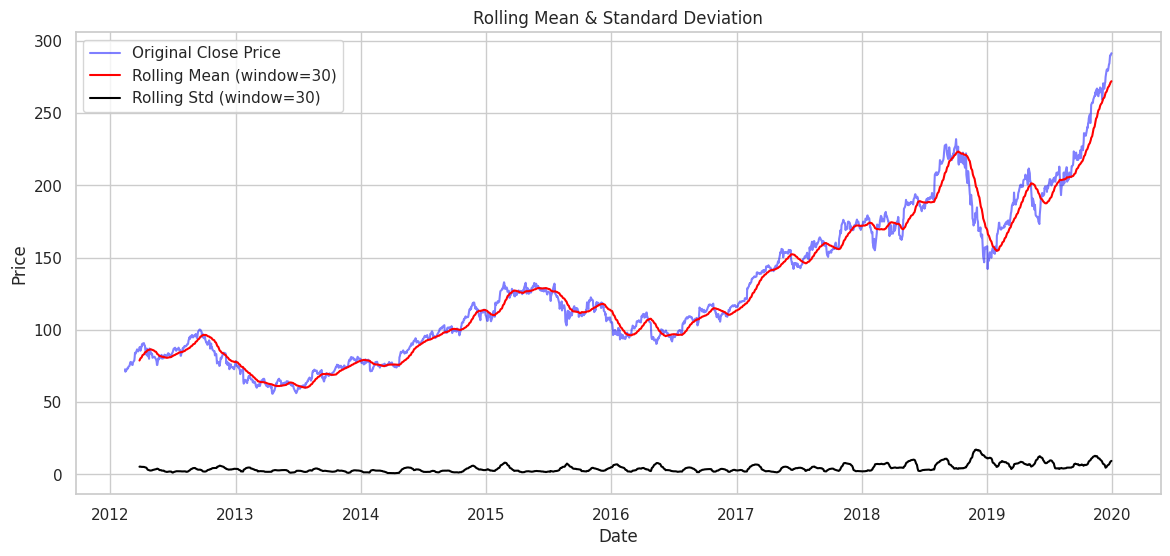

Results of Augmented Dickey-Fuller Test:


/tmp/ipykernel_2706/2790038162.py:22: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_test = adfuller(timeseries, autolag='AIC')


,Values
Test Statistic,1.389971
p-value,0.997068
#Lags Used,9.000000
Number of Observations Used,1972.000000
Critical Value (1%),-3.433670
Critical Value (5%),-2.863007
Critical Value (10%),-2.567551


Conclusion: Fail to reject the null hypothesis (H0). The time series is non-stationary.


In [25]:
from statsmodels.tsa.stattools import adfuller

# Function to perform diagnostic checks on a single sequence time series
def test_stationarity(timeseries, window=30):
    # Calculate rolling metrics to check visual alignment over time
    rolling_mean = timeseries.rolling(window=window).mean()
    rolling_std = timeseries.rolling(window=window).std()

    # Display temporal trend changes alongside rolling statistics
    plt.figure(figsize=(14, 6))
    plt.plot(timeseries, color='blue', label='Original Close Price', alpha=0.5)
    plt.plot(rolling_mean, color='red', label=f'Rolling Mean (window={window})')
    plt.plot(rolling_std, color='black', label=f'Rolling Std (window={window})')
    plt.title('Rolling Mean & Standard Deviation')
    plt.xlabel('Date')
    plt.ylabel('Price')
    plt.legend(loc='best')
    plt.grid(True)
    plt.show()

    # Execute statsmodels Augmented Dickey-Fuller (ADF) stationarity test
    print("Results of Augmented Dickey-Fuller Test:")
    adf_test = adfuller(timeseries, autolag='AIC')
    results = pd.Series(adf_test[0:4], index=['Test Statistic', 'p-value', '#Lags Used', 'Number of Observations Used'])
    for key, value in adf_test[4].items():
        results[f'Critical Value ({key})'] = value

    display(results.to_frame(name='Values'))

    # Report outcome based on the calculated p-value threshold (0.05)
    if results['p-value'] <= 0.05:
        print("Conclusion: Reject the null hypothesis (H0). The time series is stationary.")
    else:
        print("Conclusion: Fail to reject the null hypothesis (H0). The time series is non-stationary.")

# Execute stationarity function for the raw Close price target
test_stationarity(data.set_index('Date')['Close'], window=30)

ADF Statistic: -13.5546245166807
P-value: 2.373054674893429e-25


/tmp/ipykernel_2706/1826467899.py:19: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(data['Close_Diff'].dropna())


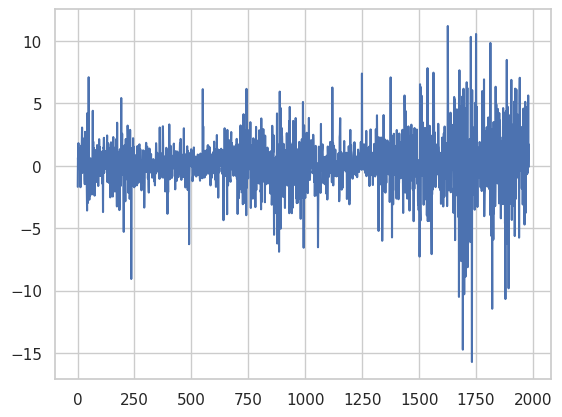

In [26]:
# Apply single differencing on Closing prices to convert a non-stationary trend to stationary
data['Close_Diff'] = data['Close'].diff()

# Render progress visual for the differenced timeline sequence
data['Close_Diff'].plot()

# Import the Dickey-Fuller statistical module
from statsmodels.tsa.stattools import adfuller

# Re-run evaluation on the differenced dataset (dropping the first missing cell)
result = adfuller(data['Close_Diff'].dropna())

# Display computed statistical values for p-value verification
print("ADF Statistic:", result[0])
print("P-value:", result[1])

### Note on outlier removal (changed)
The original notebook removed "outliers" from the **price** columns with the IQR rule. For a stock that trends upward this deletes the high-priced recent years (AAPL's 2018–19 rally), so the training data never contains the price levels seen in the test set. Tree models (Random Forest / XGBoost) cannot predict values outside the range they were trained on, which is why R² was negative. Price levels are **not** outliers, so that step has been removed.

In [35]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, random, warnings
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
warnings.filterwarnings('ignore')

# Set static seeding for reproducability
SEED = 42
np.random.seed(SEED); random.seed(SEED)

# Extract clean workspace copy
df = data[['Date','Open','High','Low','Close','Volume']].copy()
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Custom math implementation of the Relative Strength Index (RSI)
def rsi(close, n=14):
    d = close.diff()
    gain = d.clip(lower=0).ewm(alpha=1/n, adjust=False).mean()
    loss = (-d.clip(upper=0)).ewm(alpha=1/n, adjust=False).mean()
    return 100 - 100 / (1 + gain / (loss + 1e-9))

# Feature matrix generation
c = df['Close']
ret = c.pct_change()
feat = pd.DataFrame(index=df.index)

# Generate past multi-period scaled returns
for k in [1, 2, 3, 5, 10, 20]:
    feat[f'ret_{k}'] = c.pct_change(k)

# Generate rolling volatility historical values
feat['vol_10'] = ret.rolling(10).std()
feat['vol_20'] = ret.rolling(20).std()

# Distance measures relative to SMA thresholds
for k in [5, 10, 20, 50]:
    feat[f'close_to_sma{k}'] = c / c.rolling(k).mean() - 1

# Exponential trends and momentum parameters
feat['close_to_ema12'] = c / c.ewm(span=12, adjust=False).mean() - 1
feat['rsi'] = rsi(c)

# Calculate MACD and signal tracking values
macd = c.ewm(span=12, adjust=False).mean() - c.ewm(span=26, adjust=False).mean()
feat['macd_pct'] = macd / c
feat['macd_hist_pct'] = (macd - macd.ewm(span=9, adjust=False).mean()) / c

# Microstructure indicators (High-low, open-close, open-previous-close gap)
feat['hl_pct'] = (df['High'] - df['Low']) / c
feat['oc_pct'] = (c - df['Open']) / df['Open']
feat['gap_pct'] = df['Open'] / c.shift(1) - 1

# Transaction activity dynamics
feat['vol_chg'] = np.log(df['Volume']).diff()
feat['vol_ratio20'] = df['Volume'] / df['Volume'].rolling(20).mean()
feat['dow'] = df['Date'].dt.dayofweek
feat['month'] = df['Date'].dt.month

# Setup predictive objective target (Shift future return backwards to current row)
target = c.shift(-1) / c - 1
full = pd.concat([df[['Date','Close']], feat, target.rename('target')], axis=1)
full['Close_next'] = c.shift(-1)

# Keep the ultimate row as feature query for real-time projection tomorrow
last_row = full.iloc[[-1]].copy()
full = full.dropna().reset_index(drop=True)
features = list(feat.columns)
print(len(features), 'features,', len(full), 'usable rows')

# Split sequence chronologically 80% train / 20% test to protect series integrity
split = int(len(full) * 0.8)
train, test = full.iloc[:split], full.iloc[split:]
X_train, y_train = train[features], train['target']
X_test,  y_test  = test[features],  test['target']
close_t_test  = test['Close'].values         # Todays base price
actual_next   = test['Close_next'].values    # Real target close tomorrow

print(f'Train {len(train)} rows ({train.Date.min().date()} -> {train.Date.max().date()}) | '
      f'Test {len(test)} rows ({test.Date.min().date()} -> {test.Date.max().date()})')

23 features, 1932 usable rows
Train 1545 rows (2012-04-25 -> 2018-06-14) | Test 387 rows (2018-06-15 -> 2019-12-27)


In [28]:
results = {}
preds_price = {}

# Common validation pipeline to score and track model performance metrics
def evaluate(name, pred_return):
    # Reconstruct predictions from return percentages back into absolute price values
    pred_price = close_t_test * (1 + np.asarray(pred_return).ravel())
    preds_price[name] = pred_price

    # Generate error scoring metrics
    mae  = mean_absolute_error(actual_next, pred_price)
    rmse = np.sqrt(mean_squared_error(actual_next, pred_price))
    mape = np.mean(np.abs((actual_next - pred_price) / actual_next)) * 100
    r2   = r2_score(actual_next, pred_price)

    # Calculate raw directional accuracy (predicting positive or negative direction correctly)
    true_dir = np.sign(actual_next - close_t_test)
    dirn = np.nan if name.startswith('Naive') else np.mean(np.sign(pred_price - close_t_test) == true_dir) * 100

    # Record and output evaluation scores
    results[name] = {'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape, 'R2': r2, 'Directional Acc (%)': dirn}
    print(f'{name:<16} MAE {mae:7.3f} | RMSE {rmse:7.3f} | MAPE {mape:5.2f}% | R2 {r2:7.4f} | Direction {dirn:5.1f}%')

# Run Naive baseline evaluation (assuming tomorrow's return is 0)
evaluate('Naive (t-1)', np.zeros(len(test)))

Naive (t-1)      MAE   2.540 | RMSE   3.490 | MAPE  1.27% | R2  0.9869 | Direction   nan%


### Random Forest (tuned with time-series cross-validation)

In [29]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

# Grid parameter definitions for hyperparameter optimization
param_dist = {
    'n_estimators': [200, 300, 500],
    'max_depth': [3, 4, 5, 6, 8],
    'min_samples_leaf': [5, 10, 20, 40],
    'max_features': [0.3, 0.5, 0.7, 1.0],
}

# Fit random forest structure on rolling cross validation split folds
rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=SEED, n_jobs=-1),
    param_dist, n_iter=15, cv=TimeSeriesSplit(n_splits=5),
    scoring='neg_mean_squared_error', random_state=SEED, n_jobs=-1)

rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_
print('Best RF params:', rf_search.best_params_)

# Score final Random Forest predictions
evaluate('Random Forest', best_rf.predict(X_test))

Best RF params: {'n_estimators': 200, 'min_samples_leaf': 40, 'max_features': 0.3, 'max_depth': 3}
Random Forest    MAE   2.537 | RMSE   3.496 | MAPE  1.27% | R2  0.9868 | Direction  52.7%


### XGBoost (early stopping on a validation block at the end of the training period)

In [30]:
import xgboost as xgb

# Carve a contiguous validation block from train set to tune early stopping rounds
val_cut = int(len(X_train) * 0.85)
Xtr, Xval = X_train.iloc[:val_cut], X_train.iloc[val_cut:]
ytr, yval = y_train.iloc[:val_cut], y_train.iloc[val_cut:]

best = None
# Tune tree depths and step size multipliers manually on the verification chunk
for depth in [2, 3, 4]:
    for lr in [0.01, 0.03]:
        m = xgb.XGBRegressor(n_estimators=2000, learning_rate=lr, max_depth=depth,
                             subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                             reg_lambda=5.0, random_state=SEED, early_stopping_rounds=50)
        m.fit(Xtr, ytr, eval_set=[(Xval, yval)], verbose=False)
        score = m.best_score
        if best is None or score < best[0]:
            best = (score, depth, lr, m.best_iteration + 1)
print(f'Chosen: max_depth={best[1]}, lr={best[2]}, n_estimators={best[3]}')

# Re-train standard XGBoost on complete unified historical package
best_xgb = xgb.XGBRegressor(n_estimators=best[3], learning_rate=best[2], max_depth=best[1],
                            subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                            reg_lambda=5.0, random_state=SEED)
best_xgb.fit(X_train, y_train)

# Evaluate XGBoost models final projection capability
evaluate('XGBoost', best_xgb.predict(X_test))

Chosen: max_depth=3, lr=0.03, n_estimators=51
XGBoost          MAE   2.542 | RMSE   3.521 | MAPE  1.28% | R2  0.9866 | Direction  50.9%


### LSTM (multi-feature window, scalers fit on training data only)

In [31]:
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
tf.keras.utils.set_random_seed(SEED)

# Scaler parameters and sliding lookup configurations
lstm_feats = ['ret_1','ret_2','ret_5','ret_10','vol_10','vol_20','close_to_sma5','close_to_sma20',
              'close_to_ema12','rsi','macd_pct','macd_hist_pct','hl_pct','oc_pct','gap_pct','vol_chg','vol_ratio20']
WIN = 20

# Normalize historical vectors to prevent neural gradient explosion
fs = StandardScaler().fit(train[lstm_feats])
ts = StandardScaler().fit(train[['target']])
Fall = fs.transform(full[lstm_feats]).astype('float32')
Tall = ts.transform(full[['target']]).astype('float32').ravel()

# Function to group metrics into sequences of shape [samples, window_size, features]
def make_windows(start, end):
    X, y = [], []
    for i in range(max(start, WIN - 1), end):
        X.append(Fall[i - WIN + 1:i + 1]); y.append(Tall[i])
    return np.array(X), np.array(y)

X_tr_l, y_tr_l = make_windows(0, split)
X_te_l, y_te_l = make_windows(split, len(full))
assert len(X_te_l) == len(test)

# Compile Multi-Layer Recurrent Network Architecture
model = Sequential([
    Input(shape=(WIN, len(lstm_feats))),
    LSTM(32, return_sequences=True), Dropout(0.3),
    LSTM(16), Dropout(0.3),
    Dense(16, activation='relu'),
    Dense(1)
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=tf.keras.losses.Huber())

# Run optimization loop with learning rate adjustments
hist = model.fit(X_tr_l, y_tr_l, epochs=100, batch_size=32, validation_split=0.15, shuffle=False,
                 callbacks=[EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True),
                            ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5)],
                 verbose=0)
print('Stopped after', len(hist.history['loss']), 'epochs')

# Scale predicted output returns back to absolute scale and evaluate
lstm_ret = ts.inverse_transform(model.predict(X_te_l, verbose=0)).ravel()
evaluate('LSTM', lstm_ret)

Stopped after 31 epochs
LSTM             MAE   2.504 | RMSE   3.472 | MAPE  1.25% | R2  0.9870 | Direction  58.4%


### ARIMA & SARIMA (one-step-ahead, same test dates)

In [32]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Convert closing price values to natural logarithms for models
log_close = np.log(full['Close'].astype(float))
train_log = log_close.iloc[:split]

# Instantiate and fit ARIMA/SARIMA algorithms on historical log series data
arima_fit = ARIMA(train_log.values, order=(1, 1, 1)).fit()
sarima_fit = SARIMAX(train_log.values, order=(1, 1, 1), seasonal_order=(1, 1, 1, 5)).fit(disp=False)

# Map log outputs back to regular return space
def to_return(fit_res):
    app = fit_res.apply(log_close.values, refit=False)
    fitted = np.asarray(app.fittedvalues)
    idx = np.arange(split, len(full))
    nxt = np.empty(len(idx))
    nxt[:-1] = fitted[idx[:-1] + 1]
    nxt[-1] = np.asarray(app.forecast(1))[0]
    return np.exp(nxt) / full['Close'].values[idx] - 1

# Score statistical baseline variants
evaluate('ARIMA',  to_return(arima_fit))
evaluate('SARIMA', to_return(sarima_fit))

ARIMA            MAE   2.545 | RMSE   3.491 | MAPE  1.27% | R2  0.9868 | Direction  50.9%
SARIMA           MAE   2.545 | RMSE   3.493 | MAPE  1.27% | R2  0.9868 | Direction  51.9%


### Model comparison

,MAE,RMSE,MAPE (%),R2,Directional Acc (%)
LSTM,2.5039,3.4721,1.2540,0.9870,58.3979
Naive (t-1),2.5403,3.4899,1.2707,0.9869,NaN
ARIMA,2.5455,3.4914,1.2737,0.9868,50.9044
SARIMA,2.5449,3.4925,1.2734,0.9868,51.9380
Random Forest,2.5370,3.4957,1.2718,0.9868,52.7132
XGBoost,2.5424,3.5212,1.2768,0.9866,50.9044


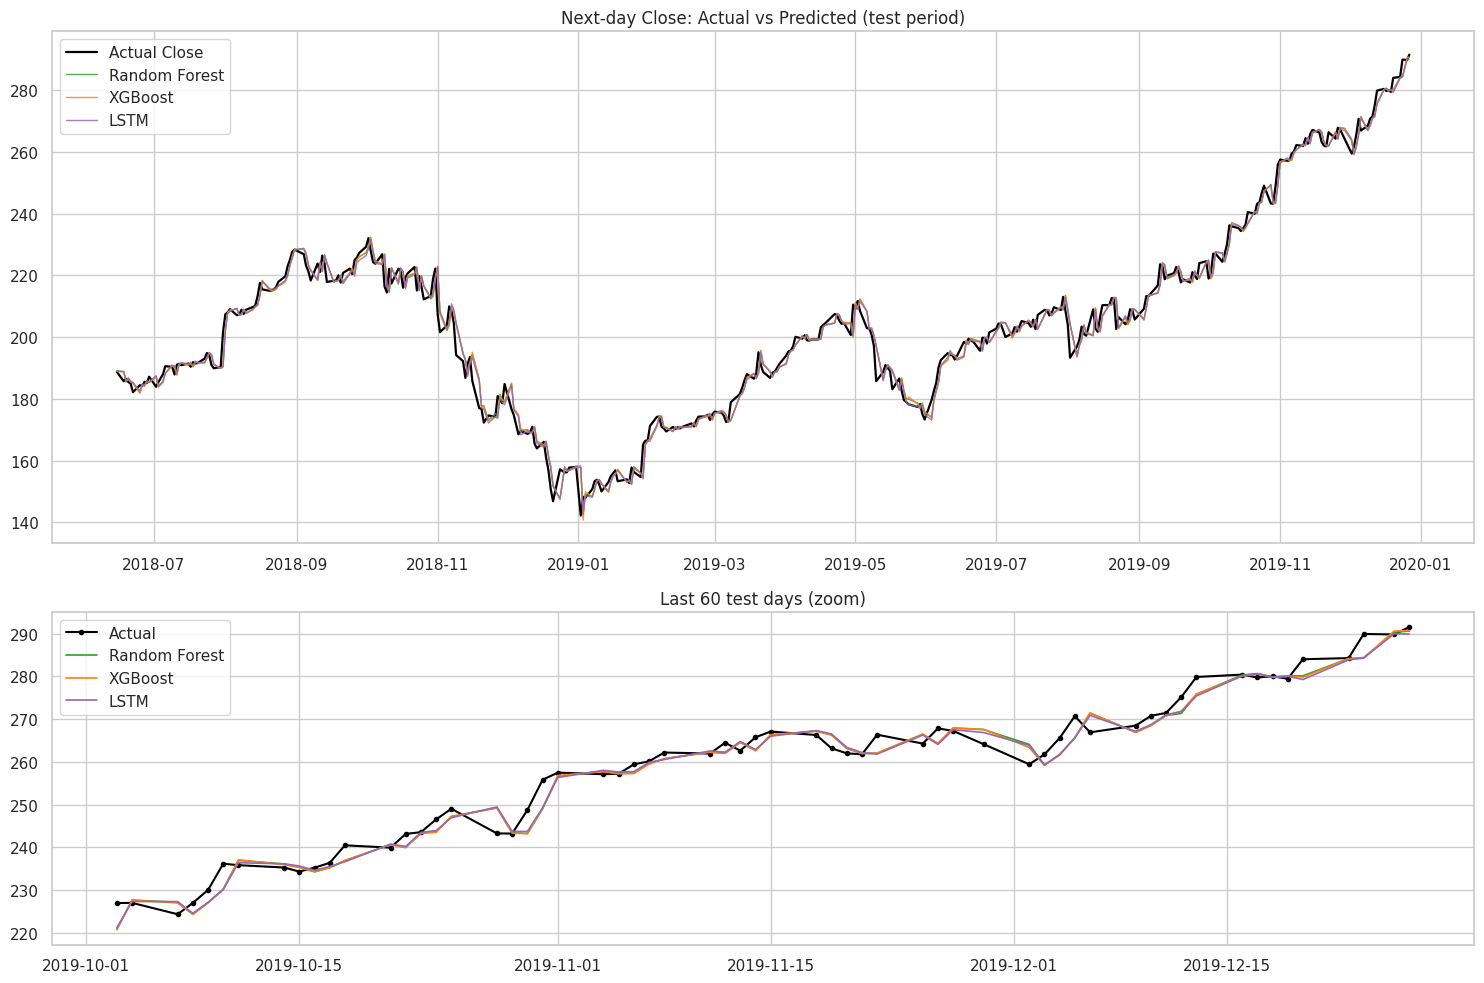

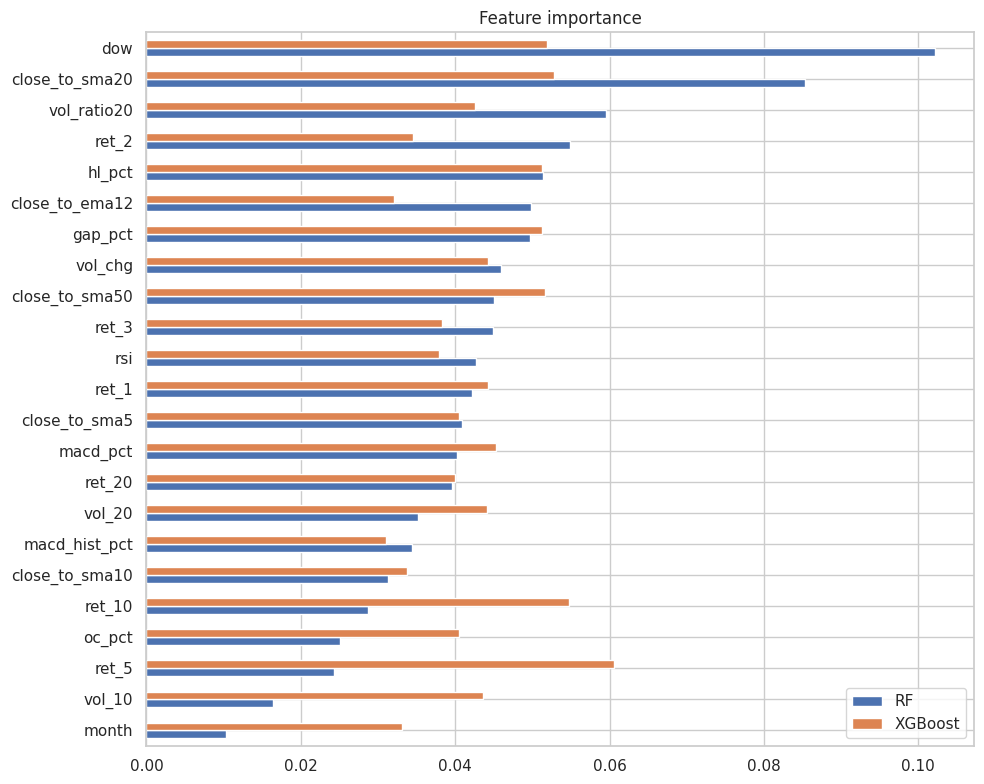

In [33]:
# Organize performance metrics across models inside a dataframe
res_df = pd.DataFrame(results).T
display(res_df.round(4).sort_values('RMSE'))

# Visual confirmation graph on general testing interval
dates = test['Date'].values + np.timedelta64(1, 'D')
fig, axes = plt.subplots(2, 1, figsize=(15, 10), gridspec_kw={'height_ratios': [2, 1.3]})
axes[0].plot(test['Date'], actual_next, color='black', lw=1.6, label='Actual Close')
for name, col in [('Random Forest','tab:green'), ('XGBoost','tab:orange'), ('LSTM','tab:purple')]:
    axes[0].plot(test['Date'], preds_price[name], color=col, lw=1, alpha=0.85, label=name)
axes[0].set_title('Next-day Close: Actual vs Predicted (test period)'); axes[0].legend(); axes[0].grid(True)

# Detailed view focusing on last 60 trading days
zoom = slice(-60, None)
axes[1].plot(test['Date'].iloc[zoom], actual_next[zoom], color='black', marker='o', ms=3, label='Actual')
for name, col in [('Random Forest','tab:green'), ('XGBoost','tab:orange'), ('LSTM','tab:purple')]:
    axes[1].plot(test['Date'].iloc[zoom], preds_price[name][zoom], color=col, lw=1.2, label=name)
axes[1].set_title('Last 60 test days (zoom)'); axes[1].legend(); axes[1].grid(True)
plt.tight_layout(); plt.show()

# Feature Importances Plot for Tree-Based Models
imp = pd.DataFrame({'RF': best_rf.feature_importances_, 'XGBoost': best_xgb.feature_importances_}, index=features)
imp.sort_values('RF').plot.barh(figsize=(10, 8), title='Feature importance'); plt.tight_layout(); plt.show()

### Next-trading-day forecast
Uses the most recent row of data (which has no known target yet) with each model.

In [34]:
# Isolate last row query features
x_last = last_row[features]
last_close = float(last_row['Close'].iloc[0])

# Forecast one-step ahead targets using fitted regressors
f_rf  = best_rf.predict(x_last)[0]
f_xgb = best_xgb.predict(x_last)[0]

# Scale and extract current prediction array for LSTM
tail = pd.concat([full[['Date'] + lstm_feats].iloc[-(WIN - 1):], last_row[['Date'] + lstm_feats]])
f_lstm = ts.inverse_transform(model.predict(fs.transform(tail[lstm_feats]).astype('float32')[None], verbose=0))[0, 0]

# Display predictions for next business day
out = pd.DataFrame({'Predicted return (%)': [f_rf*100, f_xgb*100, f_lstm*100],
                    'Predicted Close': [last_close*(1+f_rf), last_close*(1+f_xgb), last_close*(1+f_lstm)]},
                   index=['Random Forest', 'XGBoost', 'LSTM'])
print(f'Last known Close ({last_row["Date"].iloc[0].date()}): {last_close:.2f}')
display(out.round(3))

Last known Close (2019-12-30): 291.52


,Predicted return (%),Predicted Close
Random Forest,0.065,291.710
XGBoost,0.032,291.614
LSTM,0.051,291.668


### 30-Day Multi-Step Forecast (All Models including LSTM)
We will now generate the 30-day recursive forecasts using our trained **Random Forest**, **XGBoost**, and **LSTM** models.

In [38]:
import datetime
import numpy as np
import pandas as pd

# Multi-step forecasting logic to loop projections forwards over 30 days
def recursive_forecast_all(steps=30):
    # Generate upcoming forecast date index excluding weekends
    forecast_dates = []
    current_date = df['Date'].max()
    while len(forecast_dates) < steps:
        current_date += datetime.timedelta(days=1)
        if current_date.weekday() < 5:
            forecast_dates.append(current_date)

    # ---- LSTM Forecast Loop ----
    lstm_forecast_df = df.copy()
    lstm_predicted_closes = []

    for step in range(steps):
        c_series = lstm_forecast_df['Close']
        ret_series = c_series.pct_change()

        # Recalculate technical features dynamically at each step
        step_feat = pd.DataFrame(index=lstm_forecast_df.index)
        for k in [1, 2, 3, 5, 10, 20]:
            step_feat[f'ret_{k}'] = c_series.pct_change(k)
        step_feat['vol_10'] = ret_series.rolling(10).std()
        step_feat['vol_20'] = ret_series.rolling(20).std()
        for k in [5, 10, 20, 50]:
            step_feat[f'close_to_sma{k}'] = c_series / c_series.rolling(k).mean() - 1
        step_feat['close_to_ema12'] = c_series / c_series.ewm(span=12, adjust=False).mean() - 1
        step_feat['rsi'] = rsi(c_series)
        macd_s = c_series.ewm(span=12, adjust=False).mean() - c_series.ewm(span=26, adjust=False).mean()
        step_feat['macd_pct'] = macd_s / c_series
        step_feat['macd_hist_pct'] = (macd_s - macd_s.ewm(span=9, adjust=False).mean()) / c_series
        step_feat['hl_pct'] = (lstm_forecast_df['High'] - lstm_forecast_df['Low']) / c_series
        step_feat['oc_pct'] = (c_series - lstm_forecast_df['Open']) / lstm_forecast_df['Open']
        step_feat['gap_pct'] = lstm_forecast_df['Open'] / c_series.shift(1) - 1
        step_feat['vol_chg'] = np.log(lstm_forecast_df['Volume']).diff()
        step_feat['vol_ratio20'] = lstm_forecast_df['Volume'] / lstm_forecast_df['Volume'].rolling(20).mean()
        step_feat['dow'] = lstm_forecast_df['Date'].dt.dayofweek
        step_feat['month'] = lstm_forecast_df['Date'].dt.month

        # Slice final window features, scale and predict tomorrow
        last_win_feat = step_feat.iloc[-WIN:][lstm_feats]
        scaled_feat = fs.transform(last_win_feat).astype('float32')[None, :, :]
        scaled_pred = model.predict(scaled_feat, verbose=0)
        pred_ret = ts.inverse_transform(scaled_pred).ravel()[0]

        # Reconstruct price based on return percentage prediction
        last_close_val = float(c_series.iloc[-1])
        next_close_val = last_close_val * (1 + pred_ret)
        lstm_predicted_closes.append(next_close_val)

        # Append prediction as a new row
        new_row = {
            'Date': forecast_dates[step],
            'Open': last_close_val,
            'High': max(last_close_val, next_close_val),
            'Low': min(last_close_val, next_close_val),
            'Close': next_close_val,

            'Volume': lstm_forecast_df['Volume'].iloc[-1]
        }
        lstm_forecast_df = pd.concat([lstm_forecast_df, pd.DataFrame([new_row])], ignore_index=True)

    # ---- Tree Models Forecasts ----
    rf_forecast_df = recursive_forecast('Random Forest', best_rf, steps=30)
    xgb_forecast_df = recursive_forecast('XGBoost', best_xgb, steps=30)

    # Package all forecasts into a unified dataframe
    final_forecast = pd.DataFrame({
        'Date': forecast_dates,
        'RF Close': rf_forecast_df['Predicted_Close'],
        'XGBoost Close': xgb_forecast_df['Predicted_Close'],
        'LSTM Close': lstm_predicted_closes
    })
    return final_forecast

all_forecasts = recursive_forecast_all(steps=30)
display(all_forecasts.head(10))

,Date,RF Close,XGBoost Close,LSTM Close
0,2019-12-31,291.710160,291.614136,291.668091
1,2020-01-01,291.912976,291.668396,291.848572
2,2020-01-02,292.033188,291.687256,292.051056
3,2020-01-03,292.137788,291.706116,292.265228
4,2020-01-06,292.609474,292.263397,292.481506
5,2020-01-07,292.709329,292.282288,292.688843
6,2020-01-08,292.796587,292.301178,292.877075
7,2020-01-09,292.880908,292.320068,293.003693
8,2020-01-10,292.955487,292.338959,292.961578
9,2020-01-13,293.345829,292.789795,292.708923


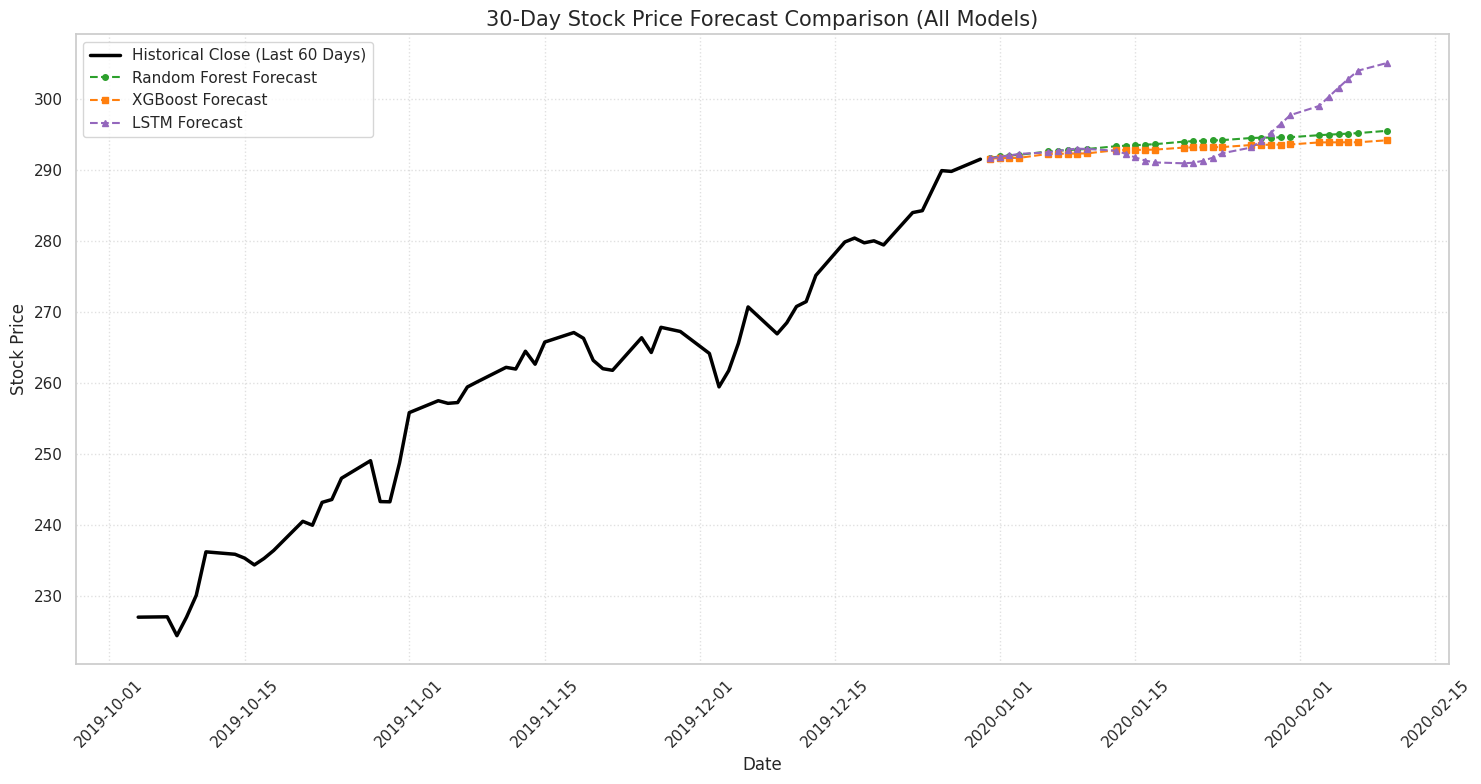

In [39]:
import matplotlib.pyplot as plt

# Slice the last 60 days of known actual values
hist_subset = df.iloc[-60:]

# Render graphical comparison of the projections
plt.figure(figsize=(15, 8))
plt.plot(hist_subset['Date'], hist_subset['Close'], color='black', label='Historical Close (Last 60 Days)', lw=2.5)
plt.plot(all_forecasts['Date'], all_forecasts['RF Close'], color='tab:green', linestyle='--', marker='o', ms=4, label='Random Forest Forecast')
plt.plot(all_forecasts['Date'], all_forecasts['XGBoost Close'], color='tab:orange', linestyle='--', marker='s', ms=4, label='XGBoost Forecast')
plt.plot(all_forecasts['Date'], all_forecasts['LSTM Close'], color='tab:purple', linestyle='--', marker='^', ms=4, label='LSTM Forecast')

plt.title('30-Day Stock Price Forecast Comparison (All Models)', fontsize=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Stock Price', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()